In [1]:
import os, copy, json, time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets
from torchvision.utils import make_grid
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure
from torchmetrics.image.fid import FrechetInceptionDistance

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

cuda NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
MODEL_NAME = "ddpm"
DATA_DIR = "data"
CKPT_DIR = "checkpoints"
FIG_DIR = "figures"
RESULTS_DIR = "results"
for d in (DATA_DIR, CKPT_DIR, FIG_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

BATCH_SIZE = 128
ORIGINAL_DIM = 28 * 28
TIMESTEPS = 1000
BETA_START = 1e-4
BETA_END = 0.02
MAX_EPOCHS = 30
LEARN_RATE = 2e-4

In [3]:
train_raw = datasets.FashionMNIST(DATA_DIR, train=True, download=True)
test_raw = datasets.FashionMNIST(DATA_DIR, train=False, download=True)
images = torch.cat([train_raw.data, test_raw.data]).unsqueeze(1).float() / 255.0
labels = torch.cat([train_raw.targets, test_raw.targets])
full = TensorDataset(images, labels)

n_train, n_val = int(0.8 * len(full)), int(0.1 * len(full))
n_test = len(full) - n_train - n_val
train_set, val_set, test_set = random_split(
    full, [n_train, n_val, n_test], generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
test_targets = labels[torch.tensor(test_set.indices)]
VIS_IDX = [int(torch.nonzero(test_targets == c)[0]) for c in range(10)]
x_vis = torch.stack([test_set[i][0] for i in VIS_IDX])
x_a, x_b = x_vis[1:2], x_vis[9:10]
ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
print(f"train={len(train_set)}  val={len(val_set)}  test={len(test_set)}")

train=56000  val=7000  test=7000


In [4]:
def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def reconstruction_metrics(reconstruct, loader):
    psnr = PeakSignalNoiseRatio(data_range=1.0).to(device)
    ssim = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)
    se, count = 0.0, 0
    for x, _ in loader:
        x = x.to(device)
        x_hat = reconstruct(x).clamp(0, 1)
        se += F.mse_loss(x_hat, x, reduction="sum").item()
        count += x.numel()
        psnr.update(x_hat, x)
        ssim.update(x_hat, x)
    return {"test_mse": se / count, "test_psnr": psnr.compute().item(), "test_ssim": ssim.compute().item()}


@torch.no_grad()
def compute_fid(generate, n_samples=len(test_set), batch=250):
    fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
    for x, _ in test_loader:
        fid.update(x.to(device).repeat(1, 3, 1, 1), real=True)
    done = 0
    while done < n_samples:
        b = min(batch, n_samples - done)
        fid.update(generate(b).clamp(0, 1).repeat(1, 3, 1, 1), real=False)
        done += b
    return fid.compute().item()


@torch.no_grad()
def measure_latency(fn, n_warmup=5, n_runs=20):
    for _ in range(n_warmup):
        fn()
    sync()
    start = time.perf_counter()
    for _ in range(n_runs):
        fn()
    sync()
    return (time.perf_counter() - start) / n_runs * 1000


def show_grid(images, nrow, title=None):
    grid = make_grid(images.detach().cpu().clamp(0, 1), nrow=nrow, padding=2, pad_value=1.0)
    plt.figure(figsize=(grid.shape[2] / 40, grid.shape[1] / 40))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


def plot_history(history, keys):
    plt.figure(figsize=(6, 3.5))
    for k in keys:
        plt.plot(range(1, len(history[k]) + 1), history[k], label=k)
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.legend()
    plt.show()


def save_results(results, outputs):
    with open(os.path.join(RESULTS_DIR, f"{MODEL_NAME}.json"), "w") as f:
        json.dump(results, f, indent=2)
    torch.save(outputs, os.path.join(RESULTS_DIR, f"{MODEL_NAME}_outputs.pt"))


def print_results(results):
    print(json.dumps({k: v for k, v in results.items() if k != "loss_history"}, indent=2))


x_latency = next(iter(test_loader))[0][:64].to(device)

In [5]:
betas = torch.linspace(BETA_START, BETA_END, TIMESTEPS, device=device)
alphas = 1 - betas
alpha_bar = torch.cumprod(alphas, dim=0)


def q_sample(x0, t, noise):
    ab = alpha_bar[t].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise


class SinusoidalEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-np.log(10000) * torch.arange(half, device=t.device) / half)
        args = t.float()[:, None] * freqs[None]
        return torch.cat([args.sin(), args.cos()], dim=1)


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.t_proj = nn.Linear(t_dim, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, t):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.t_proj(t)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class UNet(nn.Module):
    def __init__(self, ch=64, t_dim=256):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalEmbedding(ch), nn.Linear(ch, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim))
        self.inc = nn.Conv2d(1, ch, 3, padding=1)
        self.down1 = ResBlock(ch, ch, t_dim)
        self.pool1 = nn.Conv2d(ch, ch, 4, 2, 1)
        self.down2 = ResBlock(ch, ch * 2, t_dim)
        self.pool2 = nn.Conv2d(ch * 2, ch * 2, 4, 2, 1)
        self.mid1 = ResBlock(ch * 2, ch * 2, t_dim)
        self.mid2 = ResBlock(ch * 2, ch * 2, t_dim)
        self.up2 = nn.ConvTranspose2d(ch * 2, ch * 2, 4, 2, 1)
        self.dec2 = ResBlock(ch * 4, ch, t_dim)
        self.up1 = nn.ConvTranspose2d(ch, ch, 4, 2, 1)
        self.dec1 = ResBlock(ch * 2, ch, t_dim)
        self.out = nn.Sequential(nn.GroupNorm(8, ch), nn.SiLU(), nn.Conv2d(ch, 1, 3, padding=1))

    def forward(self, x, t):
        t = self.time_mlp(t)
        x = self.inc(x)
        h1 = self.down1(x, t)
        h2 = self.down2(self.pool1(h1), t)
        x = self.mid2(self.mid1(self.pool2(h2), t), t)
        x = self.dec2(torch.cat([self.up2(x), h2], dim=1), t)
        x = self.dec1(torch.cat([self.up1(x), h1], dim=1), t)
        return self.out(x)

In [6]:
def ddpm_loss(model, x0, generator=None):
    t = torch.randint(0, TIMESTEPS, (x0.size(0),), device=device, generator=generator)
    noise = torch.randn(x0.shape, device=device, generator=generator)
    return F.mse_loss(model(q_sample(x0, t, noise), t), noise)


def train(model, optimizer, x0):
    loss = ddpm_loss(model, x0)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss.item()


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    g = torch.Generator(device=device).manual_seed(SEED)
    loss_list = [ddpm_loss(model, x.to(device) * 2 - 1, g).item() for x, _ in loader]
    return np.mean(loss_list)


def train_ddpm_loop(model, opt, loader, epochs):
    history = {"train_loss": [], "val_loss": []}
    epoch_times = []
    for epoch in range(epochs):
        model.train()
        loss_list = []
        sync()
        start = time.perf_counter()
        for x, _ in loader:
            loss_list.append(train(model, opt, x.to(device) * 2 - 1))
        sync()
        epoch_times.append(time.perf_counter() - start)

        history["train_loss"].append(float(np.mean(loss_list)))
        history["val_loss"].append(float(evaluate(model, val_loader)))
        print(f"Epoch[{epoch + 1} / {epochs}], Loss : {history['train_loss'][-1]:.6f}, "
              f"Val Loss : {history['val_loss'][-1]:.6f}, Time : {epoch_times[-1]:.1f}s")
    return history, epoch_times


@torch.no_grad()
def sample(n, trajectory_every=None):
    x = torch.randn(n, 1, 28, 28, device=device)
    trajectory = [x.cpu()]
    for i in reversed(range(TIMESTEPS)):
        t = torch.full((n,), i, device=device, dtype=torch.long)
        eps = ddpm(x, t)
        mean = (x - betas[i] / (1 - alpha_bar[i]).sqrt() * eps) / alphas[i].sqrt()
        x = mean + betas[i].sqrt() * torch.randn_like(x) if i > 0 else mean
        if trajectory_every and i % trajectory_every == 0:
            trajectory.append(x.clamp(-1, 1).cpu())
    x = (x.clamp(-1, 1) + 1) / 2
    if trajectory_every:
        return x, (torch.stack(trajectory) + 1) / 2
    return x

In [7]:
ddpm = UNet().to(device)
ddpm_optimizer = torch.optim.Adam(ddpm.parameters(), lr=LEARN_RATE)
print("parameters:", sum(p.numel() for p in ddpm.parameters()))

history, epoch_times = train_ddpm_loop(ddpm, ddpm_optimizer, train_loader, MAX_EPOCHS)
torch.save(ddpm.state_dict(), os.path.join(CKPT_DIR, f"{MODEL_NAME}.pt"))

parameters: 2104065


Epoch[1 / 30], Loss : 0.088674, Val Loss : 0.056363, Time : 24.0s


Epoch[2 / 30], Loss : 0.053153, Val Loss : 0.048551, Time : 23.3s


Epoch[3 / 30], Loss : 0.047392, Val Loss : 0.045598, Time : 23.2s


Epoch[4 / 30], Loss : 0.045045, Val Loss : 0.043600, Time : 23.2s


Epoch[5 / 30], Loss : 0.043774, Val Loss : 0.042298, Time : 23.2s


... (21 outputs left out)

Epoch[27 / 30], Loss : 0.037077, Val Loss : 0.036519, Time : 23.2s


Epoch[28 / 30], Loss : 0.036585, Val Loss : 0.036547, Time : 23.1s


Epoch[29 / 30], Loss : 0.036350, Val Loss : 0.036086, Time : 23.2s


Epoch[30 / 30], Loss : 0.036594, Val Loss : 0.036152, Time : 23.1s


In [8]:
ddpm.eval()
results = {"model": MODEL_NAME, "latent_dim": "28x28", "timesteps": TIMESTEPS,
           "train_time_per_epoch_s": float(np.mean(epoch_times)),
           "test_mse": None, "test_psnr": None, "test_ssim": None}
results["latency_ms_batch64"] = measure_latency(lambda: sample(64), n_warmup=1, n_runs=3)
results["fid"] = compute_fid(sample)
results["loss_history"] = history
print_results(results)

{
  "model": "ddpm",
  "latent_dim": "28x28",
  "timesteps": 1000,
  "train_time_per_epoch_s": 23.185452180000116,
  "test_mse": null,
  "test_psnr": null,
  "test_ssim": null,
  "latency_ms_batch64": 7254.115899999306,
  "fid": 17.33713150024414
}


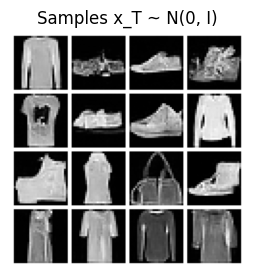

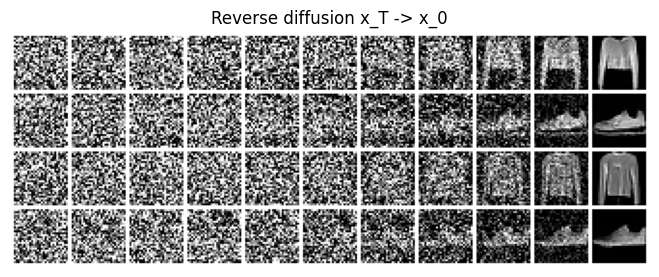

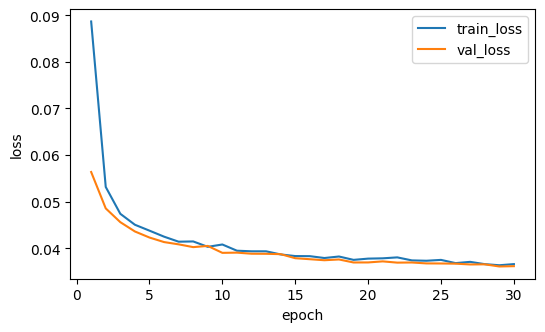

In [9]:
set_seed()
samples = sample(16).cpu()
_, trajectory = sample(4, trajectory_every=TIMESTEPS // 10)

show_grid(samples, nrow=4, title="Samples x_T ~ N(0, I)")
show_grid(trajectory.transpose(0, 1).reshape(-1, 1, 28, 28), nrow=trajectory.shape[0],
          title="Reverse diffusion x_T -> x_0")
plot_history(history, ["train_loss", "val_loss"])

In [10]:
save_results(results, {"samples": samples, "trajectory": trajectory})